---
title: AR models (estimation, inference and prediction)
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg

## GNP Dataset 

The following dataset is from FRED: https://fred.stlouisfed.org/series/GNP. This is a quarterly dataset (there are four quarters in each year).

    observation_date        GNP
0         1947-01-01    244.142
1         1947-04-01    247.063
2         1947-07-01    250.716
3         1947-10-01    260.981
4         1948-01-01    267.133
..               ...        ...
313       2025-04-01  30576.464
314       2025-07-01  31145.018
315       2025-10-01  31508.490
316       2026-01-01  31885.228
317       2026-04-01  32559.355

[318 rows x 2 columns]


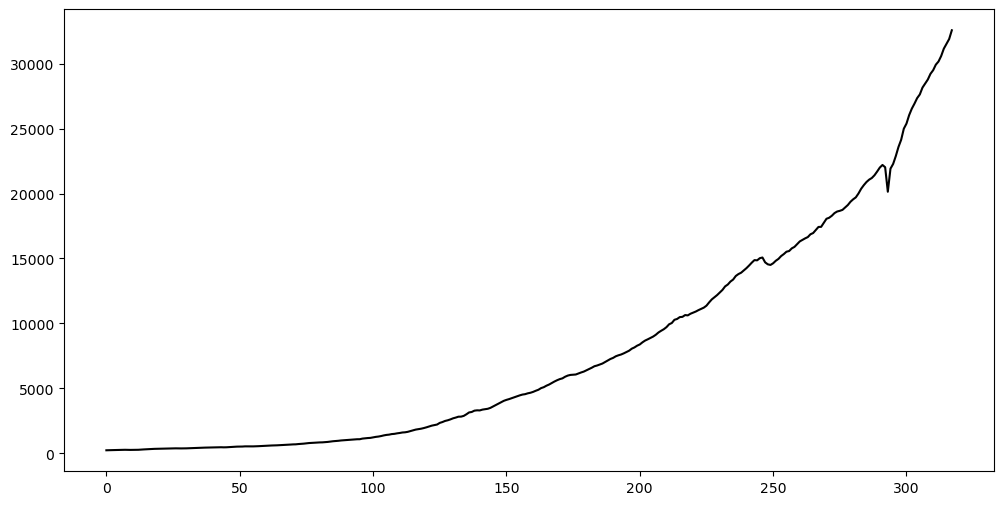

In [2]:
gnp = pd.read_csv("GNP_01Nov2026.csv")
print(gnp)
y = gnp['GNP']
plt.figure(figsize = (12, 6))
plt.plot(y, color = 'black')
plt.show()

Let us reserve the last 16 observations (corresponding to the most recent 4 years) for testing purposes. We shall fit models to the rest of the data, and then evaluate prediction accuracy on the last 16 observations.

In [3]:
n = len(y)
tme = range(1, n+1)

n_test = 22

n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]


In [4]:
print(y_train)

0        244.142
1        247.063
2        250.716
3        260.981
4        267.133
         ...    
291    22195.823
292    22021.310
293    20136.201
294    21912.369
295    22277.634
Name: GNP, Length: 296, dtype: float64


## Model One: AR(p) directly on the training data

As seen in class, AR(p) can be fit in two ways. Either by using the AutoReg function (from the library statsmodels), or by manually creating $y$ and $X$ and then running OLS. Both methods give identical parameter estimates. But the standard errors will be slightly different (also AutoReg will use $z$-scores while OLS uses $t$-scores). Below we fit the AR(2) model for the GNP data using both these methods, and compare the results obtained. 

In [5]:
p = 2
armod_sm = AutoReg(y_train, lags = p, trend = 'c').fit()
#trend = 'c' will fit the model y_t = phi_0 + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \epsilon_t
#trend = 'n' will fit the model y_t = \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \epsilon_t (note there is no intercept term phi_0)
#the default choice is trend = 'c' so we can just drop it if we want
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(2)   Log Likelihood               -1911.520
Method:               Conditional MLE   S.D. of innovations            161.230
Date:                Sun, 01 Nov 2026   AIC                           3831.040
Time:                        14:16:45   BIC                           3845.774
Sample:                             2   HQIC                          3836.940
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.5156     13.255      2.076      0.038       1.537      53.494
GNP.L1         0.7779      0.057     13.681      0.000       0.666       0.889
GNP.L2         0.2322      0.057      4.050      0.0

Next let us fit the same model by running OLS (after creating the response vector and the design matrix).

In [6]:
n_train = len(y_train)
yreg = y_train[p:] #these are the response values in the autoregression
Xmat = np.ones((n_train-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y_train[p-j : n_train-j]
    Xmat = np.column_stack([Xmat, col])

armod = sm.OLS(yreg, Xmat).fit()
print(armod.summary())

                            OLS Regression Results                            
Dep. Variable:                    GNP   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 2.424e+05
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:16:45   Log-Likelihood:                -1911.5
No. Observations:                 294   AIC:                             3829.
Df Residuals:                     291   BIC:                             3840.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.5156     13.323      2.065      0.0

Check that the parameter estimates are the same. The standard errors are quite close to each other. One of them gives z-scores while the other gives t-scores:

In [7]:
print(np.column_stack([armod.params, armod_sm.params]))
print(np.column_stack([armod.bse, armod_sm.bse])) #these are the standard errors

[[27.5155705  27.5155705 ]
 [ 0.77786203  0.77786203]
 [ 0.23215963  0.23215963]]
[[13.32273534 13.25458791]
 [ 0.05714868  0.05685635]
 [ 0.05761661  0.05732189]]


You are free to use either of these two methods while working with data. 

### Determination of the order $p$

One practical aspect of fitting AR(p) models is the determination of the order $p$. When $p$ increases, the models become more complicated and can overfit the data. The following heuristic can be used to determine $p$: 
1. Initialize at $p = 1$
2. Fit the AR(p) model to the data. Look at the 95% interval for the parameter $\phi_p$. If the interval contains 0, then use $p-1$ as the order. If the interval does not contain 0, then set $p = p+1$ and repeat Step 2. 

This is a crude heuristic. For example, the intervals for $\phi_p$ could contain zero for $p = 2, 3, 4, 5$ but exclude zero for $p = 6$. The procedure would stop at $p = 2$ and select AR(1), missing the evidence for a higher-order model. A more careful approach would examine these intervals over a range of candidate orders before choosing $p$. For simplicity, we use the stopping rule above in this notebook.

Let us apply this method to the GNP training data. The first step is to fit the AR(1) model. 

In [8]:
p = 1
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(1)   Log Likelihood               -1925.538
Method:               Conditional MLE   S.D. of innovations            165.390
Date:                Sun, 01 Nov 2026   AIC                           3857.076
Time:                        14:16:47   BIC                           3868.136
Sample:                             1   HQIC                          3861.505
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         22.8771     13.505      1.694      0.090      -3.593      49.347
GNP.L1         1.0081      0.001    683.229      0.000       1.005       1.011
                                    Roots           

The 95% interval for $\phi_1$ is $[1.005, 1.011]$ which clearly does not contain zero. So we proceed to fit AR(2).

In [9]:
p = 2
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(2)   Log Likelihood               -1911.520
Method:               Conditional MLE   S.D. of innovations            161.230
Date:                Sun, 01 Nov 2026   AIC                           3831.040
Time:                        14:16:48   BIC                           3845.774
Sample:                             2   HQIC                          3836.940
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.5156     13.255      2.076      0.038       1.537      53.494
GNP.L1         0.7779      0.057     13.681      0.000       0.666       0.889
GNP.L2         0.2322      0.057      4.050      0.0

The 95% interval for $\phi_2$ is $[0.115, 0.340]$ which also does not contain 0. So we increase $p$ and proceed to fit AR(3). 

In [10]:
p = 3
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(3)   Log Likelihood               -1899.854
Method:               Conditional MLE   S.D. of innovations            158.413
Date:                Sun, 01 Nov 2026   AIC                           3809.709
Time:                        14:16:49   BIC                           3828.110
Sample:                             3   HQIC                          3817.079
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         35.7330     13.279      2.691      0.007       9.707      61.759
GNP.L1         0.7138      0.059     12.107      0.000       0.598       0.829
GNP.L2         0.0537      0.077      0.697      0.4

The 95% interval for $\phi_3$ is $[0.104, 0.387]$ which also does not contain 0. So we increase $p$ again and proceed to fit AR(4). 

In [11]:
p = 4
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(4)   Log Likelihood               -1893.770
Method:               Conditional MLE   S.D. of innovations            158.630
Date:                Sun, 01 Nov 2026   AIC                           3799.539
Time:                        14:16:50   BIC                           3821.600
Sample:                             4   HQIC                          3808.376
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         35.0905     13.491      2.601      0.009       8.648      61.533
GNP.L1         0.7126      0.059     12.056      0.000       0.597       0.828
GNP.L2         0.0386      0.085      0.452      0.6

The 95% interval for $\phi_4$ is $[-0.406, 0.266]$. This interval contains 0 which suggests that $\phi_4$ term is redundant. So we use $p = 3$ for this dataset.

### Predictions

The fitted AR(3) can be used to generate point predictions for the future 16 observations. 

In [12]:
p = 3
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(3)   Log Likelihood               -1899.854
Method:               Conditional MLE   S.D. of innovations            158.413
Date:                Sun, 01 Nov 2026   AIC                           3809.709
Time:                        14:16:52   BIC                           3828.110
Sample:                             3   HQIC                          3817.079
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         35.7330     13.279      2.691      0.007       9.707      61.759
GNP.L1         0.7138      0.059     12.107      0.000       0.598       0.829
GNP.L2         0.0537      0.077      0.697      0.4

In [13]:
k = n_test
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives the point predictions

The predictions can also be calculated manually (without using the get_prediction function) as follows (this was discussed in class).

In [14]:
#Predictions
yhat = np.concatenate([y_train.astype(float), np.full(k, -9999)]) #extend data by k placeholder values
phi_vals = armod_sm.params
for i in range(1, k+1):
    ans = phi_vals.iloc[0]
    for j in range(1, p+1):
        ans += phi_vals.iloc[j] * yhat[n_train+i-j-1]
    yhat[n_train+i-1] = ans
predvalues = yhat[n_train:]

#Check that both predictions are identical:
print(np.column_stack([predvalues, fcast_mean]))

[[22039.36972157 22039.36972157]
 [22323.29330233 22323.29330233]
 [22602.50289469 22602.50289469]
 [22758.78498024 22758.78498024]
 [22954.77407522 22954.77407522]
 [23171.35340094 23171.35340094]
 [23374.69891306 23374.69891306]
 [23579.41436709 23579.41436709]
 [23789.4327679  23789.4327679 ]
 [24000.07358443 24000.07358443]
 [24211.77849151 24211.77849151]
 [24425.57331561 24425.57331561]
 [24641.06933976 24641.06933976]
 [24858.15218942 24858.15218942]
 [25076.97022977 25076.97022977]
 [25297.52815959 25297.52815959]
 [25519.80932771 25519.80932771]
 [25743.83838536 25743.83838536]
 [25969.63318434 25969.63318434]
 [26197.20371913 26197.20371913]
 [26426.5641115  26426.5641115 ]
 [26657.72934457 26657.72934457]]


Below we plot the predictions along with the datapoints from the test set (actual last 16 observations) that we previously set aside. 

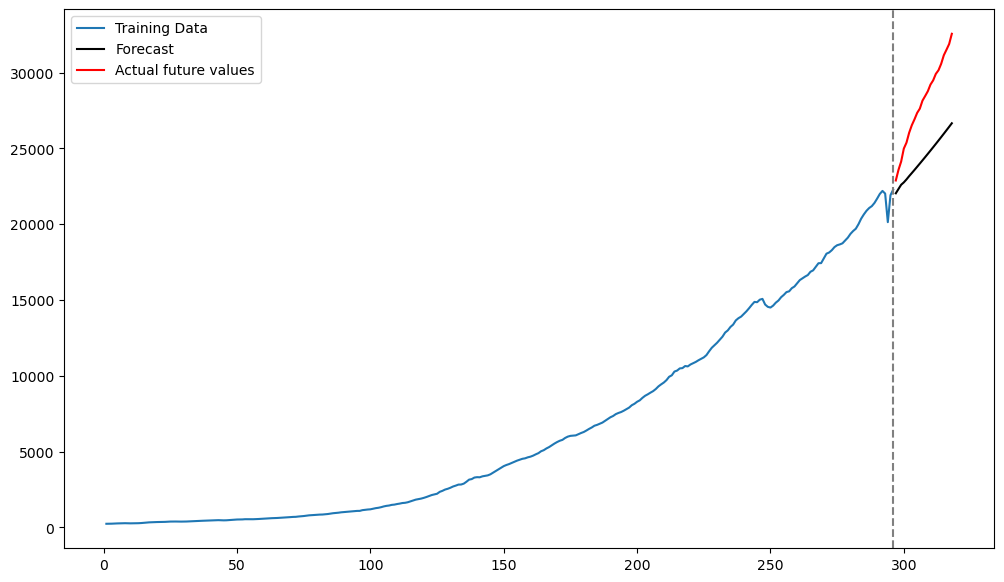

In [15]:
plt.figure(figsize = (12, 7))
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, fcast_mean, label = 'Forecast', color = 'black')
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

The predictions by the AR(3) model are decent but there are not very accurate. 

## Model Two: AR(p) model on the log(data)

Instead of fitting AR(p) models directly on the observed GNP training data, it makes sense to fit them to the logarithmed data. This method will also give predictions on the log-scale, which will need to be exponentiated to obtain predictions on the original scale. 

In [16]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

Here is the code for the automatic procedure that iteratively fits AR(p) models, starting from $p = 1$ and incrementing $p$ by 1 each time, until the 95% confidence interval for $\phi_p$ (the lag-p coefficient) includes 0 (the procedure then stops and reports the last model).

In [17]:
max_p = 20
p = 1
while p <= max_p:
    armd = AutoReg(ylog_train, lags = p).fit()
    conf_ints = armd.conf_int(alpha = 0.05)
    lower, upper = conf_ints.iloc[-1] #sometimes this is throwing an error saying that conf_ints is not a pandas array (in such cases, use conf_ints[-1,:])
    if (lower < 0 < upper):
        print(f"Stopping at p = {p} because 0 is in the phi_{p} interval")
        break
    p += 1
if p >= max_p:
    print(f"Reached p = {max_p} without finding a phi_p interval containing 0")
p = p-1 #note that if the algorithm outputs p = 4, we should take p = 3
print(p)

Stopping at p = 4 because 0 is in the phi_4 interval
3


Now let us fit the AR(p) model (with $p$ selected as above) to the logarithm of the GNP data.

In [18]:
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                    GNP   No. Observations:                  296
Model:                     AutoReg(3)   Log Likelihood                 870.590
Method:               Conditional MLE   S.D. of innovations              0.012
Date:                Sun, 01 Nov 2026   AIC                          -1731.180
Time:                        14:16:58   BIC                          -1712.780
Sample:                             3   HQIC                         -1723.811
                                  296                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0201      0.005      4.205      0.000       0.011       0.029
GNP.L1         1.1720      0.058     20.333      0.000       1.059       1.285
GNP.L2         0.0063      0.093      0.068      0.9

Below we predict the next 16 values. 

In [19]:
k = n_test
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives the point predictions

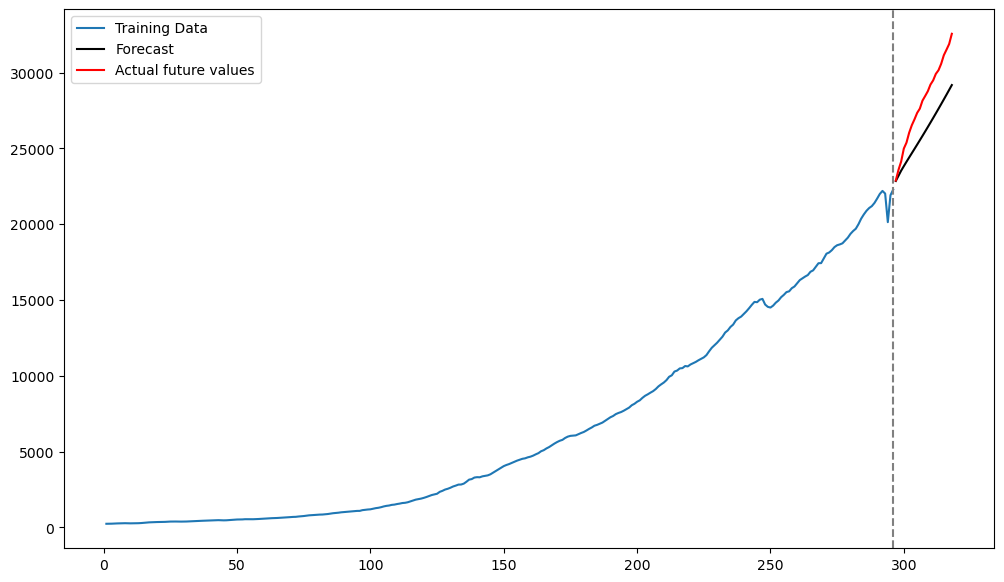

In [20]:
plt.figure(figsize = (12, 7))
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, np.exp(fcast_mean), label = 'Forecast', color = 'black') #Note the exponentiation
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

Compare these predictions with those obtained from Method One. The predictions from Model Two seem closer (compared to Model One) to the actual values but the accuracy is still not very good. 

## Model Three: Working with Differenced Data

Instead of working with log GNP data, it is common to work their differences: 
\begin{equation*}
   y_t = \log \text{GNP}_t - \log \text{GNP}_{t-1} = \log \frac{\text{GNP}_{t}}{\text{GNP}_{t-1}}
\end{equation*}
Because $\log x \approx x-1$, as we remarked previously, $100 y_t$ represents the percentage change in GNP from year $t-1$ to year $t$. 

The differenced log-data look very different from the original data and the log-data. 

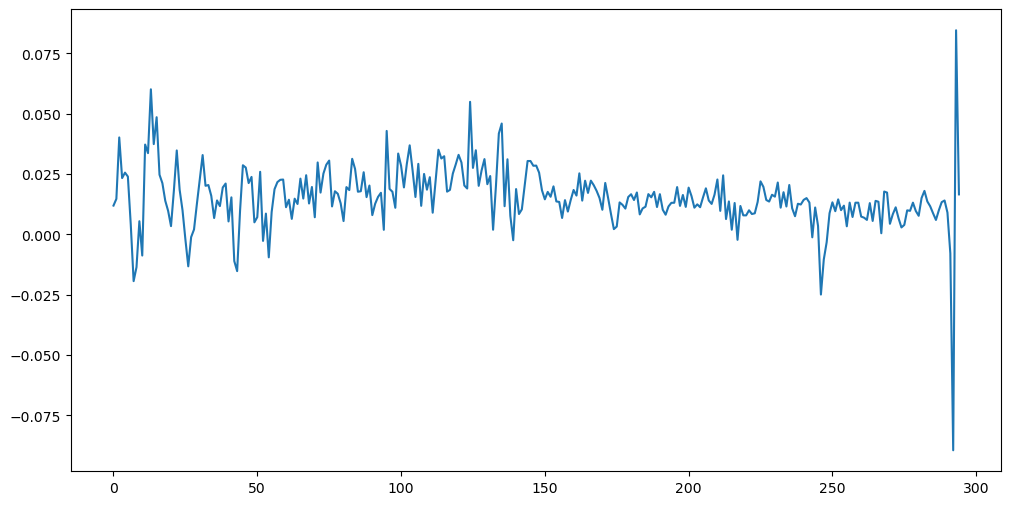

In [21]:
ylogdiff_train = np.diff(ylog_train)
plt.figure(figsize = (12, 6))
plt.plot(ylogdiff_train) 
plt.show()

Notice that the differenced log-data has  no "trend". The trend has been removed by differencing.

In [22]:
max_p = 20
p = 1
while p <= max_p:
    armd = AutoReg(ylogdiff_train, lags = p).fit()
    conf_ints = armd.conf_int(alpha = 0.05)
    lower, upper = conf_ints[-1,:]
    if (lower < 0 < upper):
        print(f"Stopping at p = {p} because 0 is in the phi_{p} interval")
        break
    p += 1
if p >= max_p:
    print(f"Reached p = {max_p} without finding a phi_p interval containing 0")
p = p-1 #note that if the algorithm outputs p = 4, we should take p = 3
print(p)

Stopping at p = 3 because 0 is in the phi_3 interval
2


We now fit the AR model with the chosen $p$.

In [23]:
armod_sm = AutoReg(ylogdiff_train, lags = p, trend = 'c').fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  295
Model:                     AutoReg(2)   Log Likelihood                 867.825
Method:               Conditional MLE   S.D. of innovations              0.013
Date:                Sun, 01 Nov 2026   AIC                          -1727.649
Time:                        14:17:04   BIC                          -1712.929
Sample:                             2   HQIC                         -1721.754
                                  295                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0092      0.001      7.021      0.000       0.007       0.012
y.L1           0.1937      0.057      3.371      0.001       0.081       0.306
y.L2           0.2073      0.060      3.434      0.0

Now we obtain predictions. We can use the same method as before to generate predictions for the future 16 values. 

In [24]:
k = n_test
fcast = armod_sm.get_prediction(start = n_train-1, end = n_train+k-2)
fcast_mean = fcast.predicted_mean #this gives the point predictions

However that these predictions are for the differenced log-data (they are not for the original data). To be clear, suppose $y_t$ denotes $\log(\text{GNP}_t)$. Then we obtained predictions for the future 16 values of $y_t - y_{t-1}$ i.e., $y_{n+1} - y_n, y_{n+2} - y_{n+1}, ..., y_{n+k} - y_{n+k-1}$. But we need predictions for $y_t$ not for these differences. To compute the predictions for $y_t$, we can simply do the following: 
\begin{equation*}
   \hat{y}_{n+1} = y_n + \widehat{y_{n+1} - y_n}
\end{equation*}
and
\begin{equation*}
   \hat{y}_{n+2} = \hat{y}_{n+1} + \widehat{y_{n+2} - y_{n+1}}
\end{equation*}
and so on recursively computing $\hat{y}_{n+3}$, $\hat{y}_{n+4}$ etc. This process is implemented in the code below. Note that we have to exponentiate the predictions for $y_t$ in the end because for $\text{GNP}_t = \exp(y_t)$.

In [25]:
last_observed_log = ylog_train.iloc[-1]
log_forecast = np.zeros(k)
log_forecast[0] = last_observed_log + fcast_mean[0]
for i in range(1, k):
    log_forecast[i] = log_forecast[i-1] + fcast_mean[i]
original_scale_forecast = np.exp(log_forecast)

Below we plot these predictions along with the actual test values. 

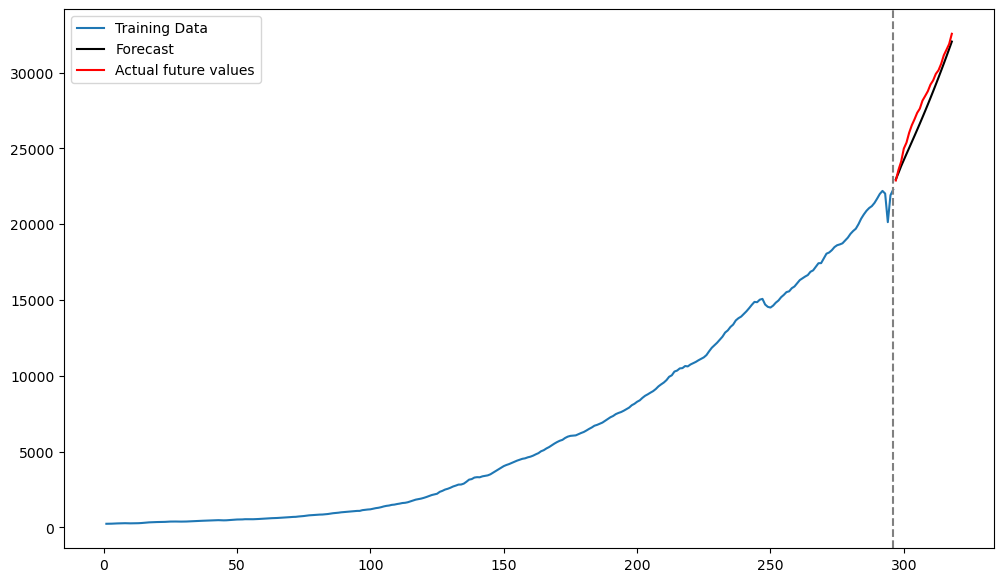

In [26]:
plt.figure(figsize = (12, 7))
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, original_scale_forecast, label = 'Forecast', color = 'black')
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

It is very interesting that these predictions are much more accurate compared to the predictions obtained by the previous two models. This suggests that AR(p) models are better for the difference log-data than for the log-data without differencing (and also for the original data).

The following is another way of obtaining the predictions for the original data from the model fitted to the differenced data. The AR(2) model that we just fitted to $y_t = \log \text{GNP}_t - \log \text{GNP}_{t-1}$ is: 
\begin{equation*}
   y_t = \hat{\phi}_0 + \hat{\phi}_1 y_{t-1} + \hat{\phi}_2 y_{t-2} + \epsilon_t
\end{equation*}
If we replace $y_t$ by $\log \text{GNP}_t - \log \text{GNP}_{t-1}$ and rewrite the equation above, we obtain:
\begin{equation*}
   \log \text{GNP}_t = \hat{\phi}_0 + (\hat{\phi}_1 + 1) \log \text{GNP}_{t-1} + \left(\hat{\phi}_2 - \hat{\phi}_1 \right) \log \text{GNP}_{t-2} - \hat{\phi}_2 \log \text{GNP}_{t-3} + \epsilon_t
\end{equation*}
Thus in terms of $\log \text{GNP}_t$, the fitted model can be interpreted as an AR(3) model. However, it is a special kind of AR(3) model (for example, the sum of the fitted coefficients for $\log \text{GNP}_{t-1}$, $\log \text{GNP}_{t-2}$, $\log \text{GNP}_{t-3}$ equals 0). We can compare this special AR(3) model to the model obtained by fitting AR(3) to the $\log \text{GNP}_t$ data:

In [27]:
phi_vals = np.array([armod_sm.params[0], armod_sm.params[1] + 1, armod_sm.params[2] - armod_sm.params[1], -armod_sm.params[2]]) #these are the fitted coefficients in the AR(3) model derived from AR(2) applied to the differences
armod_nodiff = AutoReg(ylog_train, lags = 3).fit()
print(np.column_stack([phi_vals, armod_nodiff.params]))


[[ 0.0092274   0.02008565]
 [ 1.19366576  1.17196452]
 [ 0.01364548  0.0063086 ]
 [-0.20731124 -0.17953764]]


It is interesting that the parameter estimates are somewhat similar but not exactly the same. 

With this AR(3) model for $\log \text{GNP}_t$ that is derived from the AR(2) model for $y_t = \log \text{GNP}_t - \log \text{GNP}_{t-1}$, we can obtain predictions in the usual way as follows. 

In [28]:
yhat = np.concatenate([ylog_train.astype(float), np.full(k, -9999)]) #extend data by k placeholder values
p = len(phi_vals)-1
for i in range(1, k+1):
    ans = phi_vals[0]
    for j in range(1, p+1):
        ans += phi_vals[j] * yhat[n_train+i-j-1]
    yhat[n_train+i-1] = ans
predvalues = yhat[n_train:]
print(predvalues)

[10.04129201 10.05974764 10.07875897 10.09549428 10.111904   10.12777882
 10.14348255 10.15904226 10.17453861 10.18999282 10.20542575 10.22084581
 10.23625897 10.25166813 10.26707508 10.28248077 10.29788577 10.31329036
 10.32869474 10.34409899 10.35950317 10.37490731]


These predictions coincide with the predictions obtained previously. 

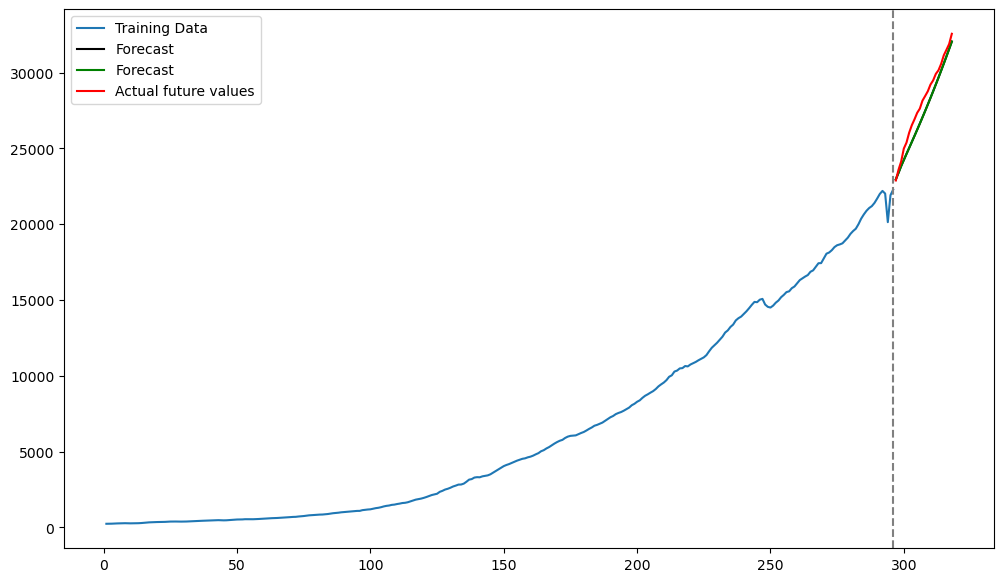

In [29]:
plt.figure(figsize = (12, 7))
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, original_scale_forecast, label = 'Forecast', color = 'black')
plt.plot(tme_test, np.exp(predvalues), label = 'Forecast', color = 'green')
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

The green and black predictions coincide above. 

To conclude, predictions from the AR(3) model applied directly to the $\log \text{GNP}$ data are different from the predictions obtained by AR(2) fitted to the differences of $\log \text{GNP}$. It is quite common, while using AR models, to work with differenced data. 

## Sensitivity to the choice of `n_test`

The code above uses `n_test = 22`. Let us now use **`n_test = 24`**, keeping the same model orders: AR(3) for GNP, AR(3) for log GNP, and AR(2) for log differences. We refit all three models to the shorter training sample; we do not repeat the order-selection procedure.

The training data now end in **2020 Q2**, at the sharp fall in GNP, instead of 2020 Q4, after the rebound. The compact code below reproduces the three forecast plots. We display only the last 60 quarters to make the differences easier to see, but use the entire training sample for fitting.

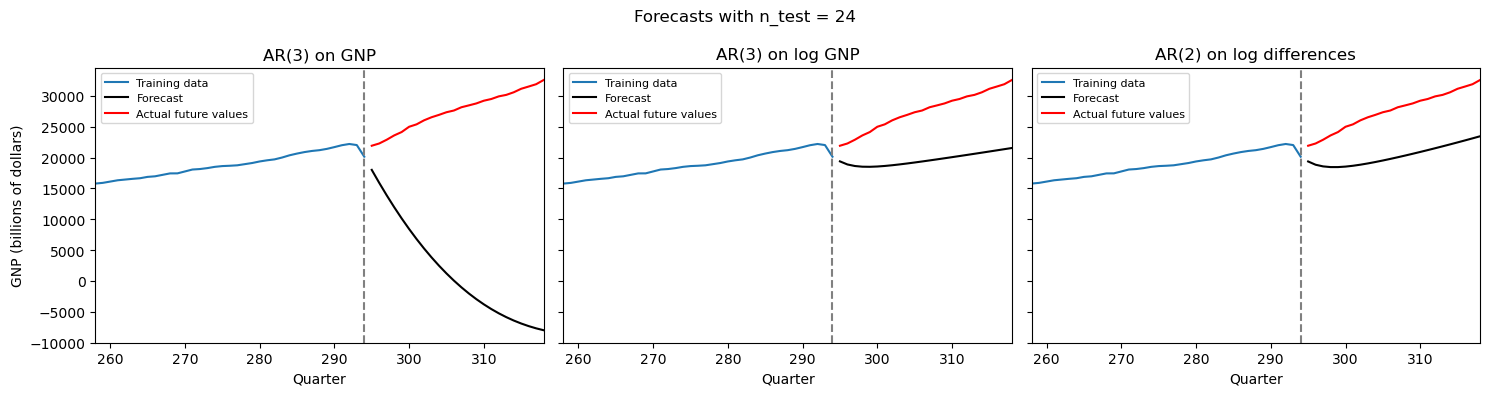

In [30]:
n_test = 24
n_train = n - n_test
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
tme_train, tme_test = tme[:n_train], tme[n_train:]

series = [y_train, np.log(y_train), np.diff(np.log(y_train))]
models = [AutoReg(z, lags=p).fit() for z, p in zip(series, [3, 3, 2])]
forecasts = [np.asarray(model.forecast(n_test)) for model in models]
forecasts[1] = np.exp(forecasts[1])
forecasts[2] = np.exp(np.log(y_train.iloc[-1]) + np.cumsum(forecasts[2]))

titles = ['AR(3) on GNP', 'AR(3) on log GNP', 'AR(2) on log differences']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, forecast, title in zip(axes, forecasts, titles):
    ax.plot(tme_train, y_train, label='Training data')
    ax.plot(tme_test, forecast, color='black', label='Forecast')
    ax.plot(tme_test, y_test, color='red', label='Actual future values')
    ax.axvline(n_train, color='gray', linestyle='--')
    ax.set(title=title, xlabel='Quarter', xlim=(n-60, n))
    ax.legend(fontsize=8)
axes[0].set_ylabel('GNP (billions of dollars)')
fig.suptitle('Forecasts with n_test = 24')
plt.tight_layout()
plt.show()

The predictions are dramatically different. The raw-data AR(3) model now predicts negative GNP, while both log-based models substantially underpredict the recovery. In particular, differencing no longer gives the close predictions seen earlier: its forecast for the final observation falls from about **32,045** to **23,444**, compared with the actual value **32,559**.

Changing `n_test` changes the data used to estimate the coefficients, the last observations that initialize the forecasts, and the forecast horizon. This example shows why good predictions on one train–test split do not guarantee good predictions on another.

### Conclusion: sensitivity of forecasts to the training period

Changing `n_test` from 22 to 24 produces dramatically different predictions, even though we keep the same model orders. In particular, the AR model fitted to log differences, which gave accurate predictions with `n_test = 22`, substantially underpredicts the future observations with `n_test = 24`. Thus, good performance on one train–test split does not guarantee good performance on another.

To understand the difference, consider where the training data end. With `n_test = 24`, the last training observation is from 2020 Q2, at the sharp fall in GNP. With `n_test = 22`, the training data include two additional quarters showing the rebound. These observations affect both the estimated coefficients and the final values used to initialize the forecasts. Since multi-step AR forecasts are computed recursively, these changes can have substantial effects on the entire predicted path. The forecast horizon also changes from 22 to 24 quarters. We are therefore comparing forecasts made from different starting points, with different information and different horizons.

This illustrates a difficulty that is **more general than AR models**. At the end of a sharp decline, a central forecasting question is whether the decline will continue, stabilize, or reverse quickly. A method using only past GNP must make assumptions about how the observed patterns will continue into the future. If subsequent behavior differs substantially from those assumptions, its predictions can be poor. The later training endpoint provides evidence of a recovery that is absent from the earlier training sample.

However, this does not mean that all forecasting methods would perform equally poorly, or that the recovery was inherently unpredictable. Other models, or additional information about economic conditions, might give better predictions. This example alone cannot determine how much of the forecast error reflects unavoidable uncertainty and how much reflects limitations of the fitted models.

Some weaknesses are specific to the models used here. The negative GNP predictions from the raw-data AR model reflect its unconstrained extrapolation: nothing in that model requires forecasts to remain positive. Modeling logarithms prevents this particular problem, but the resulting forecasts can still be inaccurate. Similarly, differencing can make a series easier to model, but it does not ensure that the fitted relationships will describe its future behavior. The earlier success of the differenced-log model therefore provides evidence of its usefulness for that particular split, rather than establishing that differencing always improves predictions.

To assess forecasting performance more reliably, we should repeat the analysis at several training endpoints. At each endpoint, we would fit the models using only the observations up to that point and compare their predictions with subsequent observations. Using the same forecast horizon at each endpoint would make the comparisons easier to interpret. This would help us assess both typical prediction accuracy and how much performance varies across periods, including periods with unusual economic changes.